# Customer Churn Prediction — End-to-End Machine Learning

This project predicts customer churn, compares baseline and tree-based classifiers, tunes hyperparameters with cross-validation, chooses a decision threshold on validation data, and evaluates the final model on an untouched test set.

**Notebook contents:** data validation, EDA, leakage-aware splitting, preprocessing pipelines, model comparison, randomized hyperparameter search, threshold analysis, multiple metrics, visualizations, permutation importance, error analysis, and model export.

**Reproducibility:** keep `customer_churn_business_dataset.csv` beside this notebook. Scores are computed at run time and are not hard-coded. A strong score on one dataset is not a guarantee of production performance.

## 1. Environment and imports

Install dependencies from `requirements_churn.txt` if needed. The optional install command is commented out to avoid changing the Python environment unexpectedly.

In [1]:
# Optional, if packages are missing:
# %pip install -U pandas numpy matplotlib seaborn scikit-learn xgboost joblib

from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
    log_loss, brier_score_loss, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibrationDisplay

RANDOM_STATE = 42
DATA_PATH = Path("customer_churn_business_dataset.csv")
OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 120})
pd.set_option("display.max_columns", 100)

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost unavailable; scikit-learn models will still run.")

print("Environment ready. XGBoost available:", XGBOOST_AVAILABLE)

Environment ready. XGBoost available: True


## 2. Load data and run quality checks

We verify the expected target exists, inspect missingness and duplicates, and confirm that the target is binary. The customer ID is an identifier and will be excluded from model features.

In [6]:
from pathlib import Path
import pandas as pd

# Dataset is stored in the data subfolder
DATA_PATH = Path("data") / "customer_churn_business_dataset.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}\n"
        "Ensure the data folder contains customer_churn_business_dataset.csv."
    )

df = pd.read_csv(DATA_PATH)

TARGET = "churn"
ID_COLUMNS = ["customer_id"]

if TARGET not in df.columns:
    raise ValueError(f"Missing target column: {TARGET}")

if df[TARGET].isna().any() or df[TARGET].nunique() != 2:
    raise ValueError("Target must be complete and binary.")

print(f"Dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

display(df.head())



Dataset: 10,000 rows × 32 columns
Exact duplicate rows: 0


,customer_id,gender,age,country,city,customer_segment,tenure_months,signup_channel,contract_type,monthly_logins,weekly_active_days,avg_session_time,features_used,usage_growth_rate,last_login_days_ago,monthly_fee,total_revenue,payment_method,payment_failures,discount_applied,price_increase_last_3m,support_tickets,avg_resolution_time,complaint_type,csat_score,escalations,email_open_rate,marketing_click_rate,nps_score,survey_response,referral_count,churn
0,CUST_00001,Male,68,Bangladesh,London,SME,22,Web,Monthly,26,7,11.762372,5,0.06,7,30,660,PayPal,1,Yes,No,4,13.354360,Service,4.0,0,0.71,0.40,27,Satisfied,1,0
1,CUST_00002,Female,57,Canada,Sydney,Individual,9,Mobile,Monthly,7,5,26.846390,1,-0.28,2,30,270,Card,1,No,Yes,1,25.140088,Billing,2.0,0,0.78,0.33,-19,Neutral,2,1
2,CUST_00003,Male,24,Germany,New York,SME,58,Web,Yearly,19,5,23.380065,6,0.13,23,20,1160,Card,2,No,No,1,27.572928,Service,3.0,0,0.35,0.49,80,Neutral,1,0
3,CUST_00004,Male,49,Australia,Dhaka,Individual,19,Mobile,Yearly,34,7,24.243136,2,-0.17,24,30,570,Bank Transfer,0,Yes,No,3,26.420822,Technical,5.0,1,0.83,0.15,100,Neutral,0,0
4,CUST_00005,Male,65,Bangladesh,Delhi,Individual,52,Web,Monthly,20,6,18.872323,2,-0.16,2,50,2600,PayPal,0,No,No,0,26.674579,Technical,4.0,0,0.65,0.44,21,Unsatisfied,1,0


In [7]:
quality = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique(dropna=False),
    }
).sort_values("missing_count", ascending=False)

display(quality)

,dtype,missing_count,missing_percent,unique_values
complaint_type,object,2045,20.45,4
customer_id,object,0,0.00,10000
gender,object,0,0.00,2
referral_count,int64,0,0.00,8
survey_response,object,0,0.00,3
nps_score,int64,0,0.00,197
marketing_click_rate,float64,0,0.00,50
email_open_rate,float64,0,0.00,81
escalations,int64,0,0.00,5
csat_score,float64,0,0.00,5


In [8]:
target_table = pd.DataFrame(
    {
        "count": df[TARGET].value_counts().sort_index(),
        "percent": (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(
            2
        ),
    }
)

display(target_table)
print(f"Observed churn rate: {df[TARGET].mean():.2%}")

,count,percent
churn,,
0,8979,89.79
1,1021,10.21


Observed churn rate: 10.21%


## 3. Exploratory data analysis

These charts show the target balance, numeric feature differences, churn rates across categorical groups, and correlations. They describe associations; they do not establish causation.

,Retained (0),Churned (1),Difference
total_revenue,1081.14,844.90,-236.24
tenure_months,30.83,24.22,-6.61
monthly_logins,20.00,16.80,-3.20
last_login_days_ago,9.38,10.59,1.21
age,45.85,46.40,0.55
csat_score,3.54,3.03,-0.51
monthly_fee,34.97,34.57,-0.40
nps_score,19.07,19.46,0.39


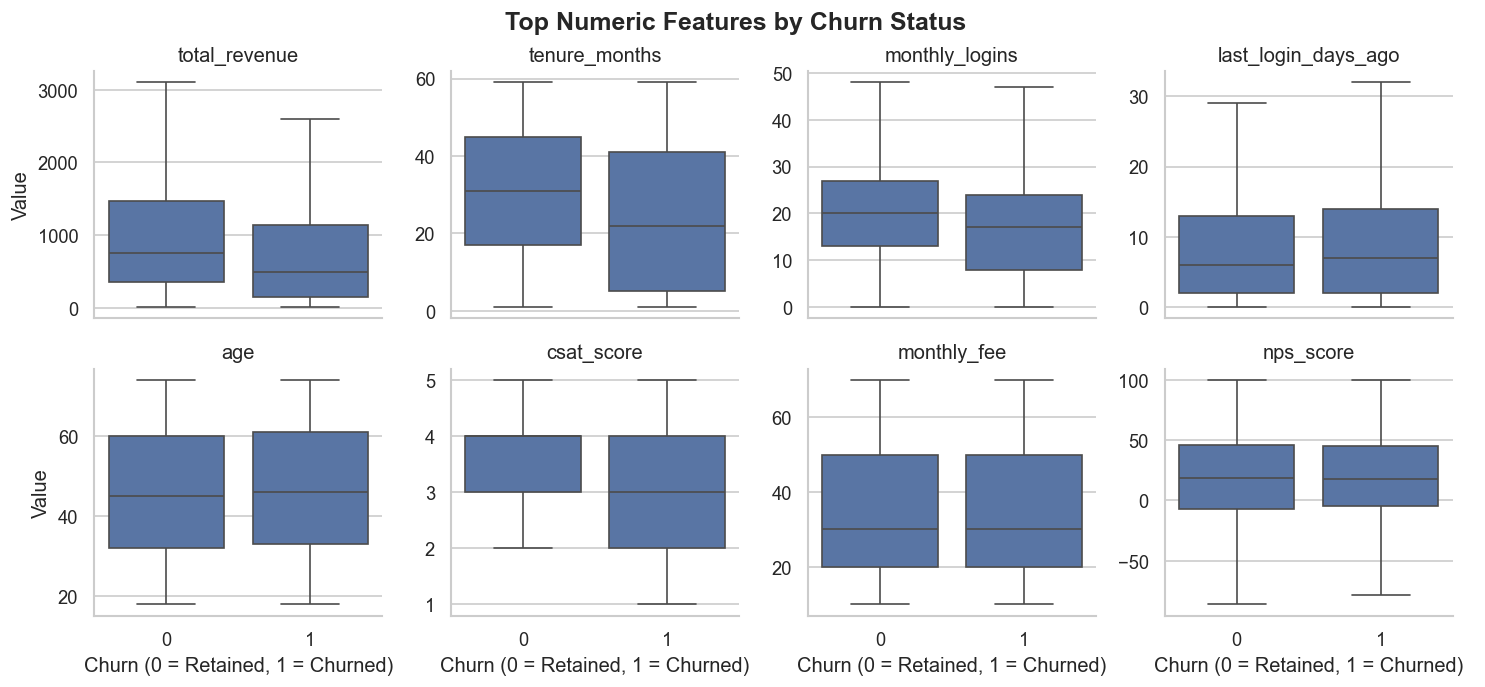

In [14]:
# Numeric Feature Analysis by Churn Status — Compact View

numeric_cols = [
    c
    for c in df.select_dtypes(include=np.number).columns
    if c != TARGET and c not in ID_COLUMNS
]

if numeric_cols:
    # One consolidated comparison table
    means = df.groupby(TARGET)[numeric_cols].mean().T
    means.columns = ["Retained (0)", "Churned (1)"]
    means["Difference"] = means["Churned (1)"] - means["Retained (0)"]
    means["Absolute Difference"] = means["Difference"].abs()

    top_features = means["Absolute Difference"].nlargest(min(8, len(means))).index

    summary = means.loc[
        top_features, ["Retained (0)", "Churned (1)", "Difference"]
    ].round(2)

    display(summary)

    # One consolidated visualization
    plot_data = df[list(top_features) + [TARGET]].melt(
        id_vars=TARGET, var_name="Feature", value_name="Value"
    )

    g = sns.catplot(
        data=plot_data,
        x=TARGET,
        y="Value",
        col="Feature",
        col_wrap=4,
        kind="box",
        sharey=False,
        height=2.8,
        aspect=1.1,
        showfliers=False,
    )

    g.set_titles("{col_name}")
    g.set_axis_labels("Churn (0 = Retained, 1 = Churned)", "Value")
    g.fig.suptitle(
        "Top Numeric Features by Churn Status", fontsize=15, fontweight="bold", y=1.02
    )

    plt.show()
else:
    print("No numeric features available for comparison.")

,Retained (0),Churned (1),Churn minus retained
age,45.850,46.401,0.551
tenure_months,30.830,24.222,-6.608
monthly_logins,19.998,16.803,-3.195
weekly_active_days,3.486,3.419,-0.067
avg_session_time,15.199,15.094,-0.105
features_used,4.987,5.026,0.040
usage_growth_rate,0.019,0.022,0.003
last_login_days_ago,9.382,10.588,1.206
monthly_fee,34.970,34.574,-0.397
total_revenue,1081.138,844.897,-236.241


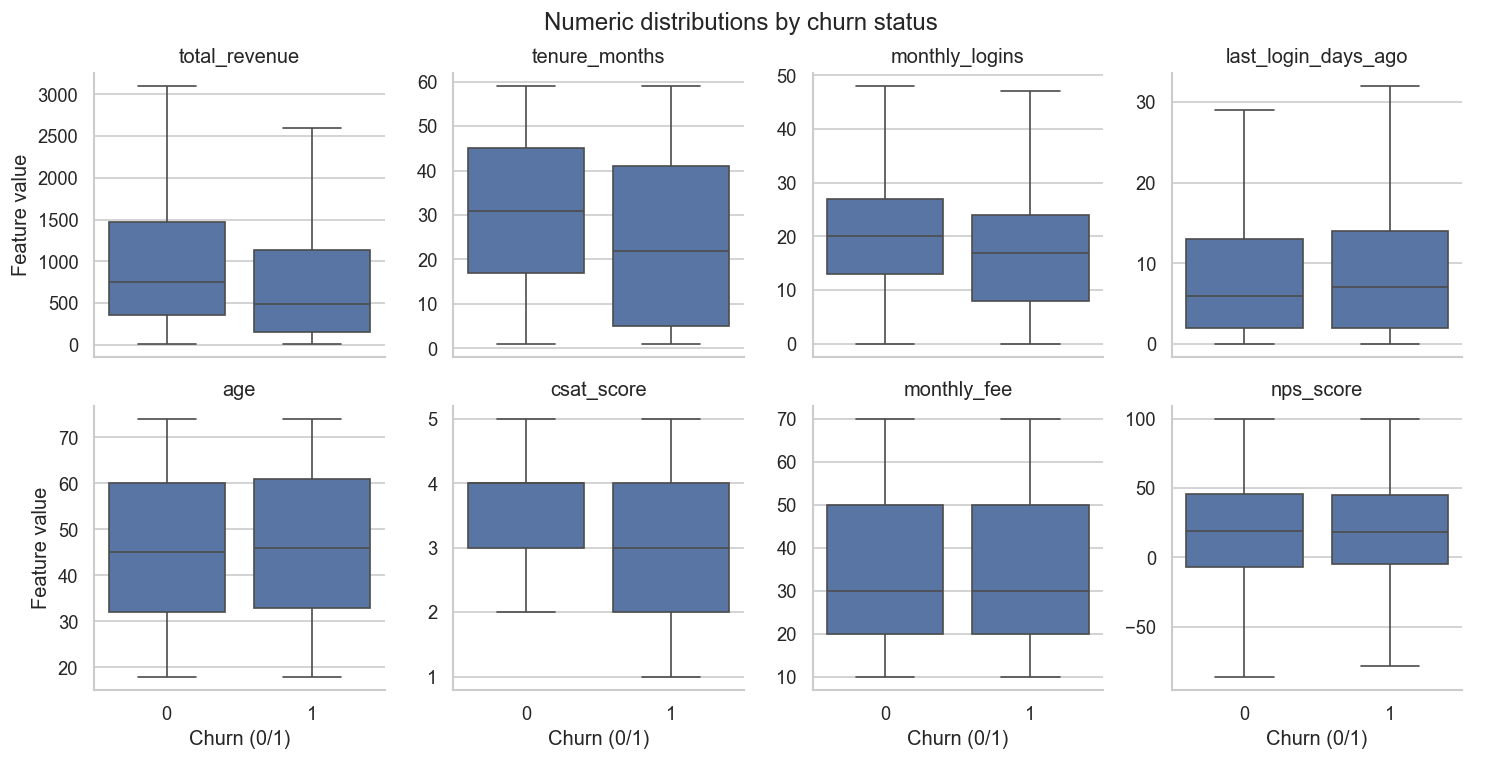

In [11]:
numeric_cols = [c for c in df.select_dtypes(include=np.number).columns if c != TARGET]
if numeric_cols:
    means = df.groupby(TARGET)[numeric_cols].mean().T
    means.columns = ["Retained (0)", "Churned (1)"]
    means["Churn minus retained"] = means["Churned (1)"] - means["Retained (0)"]
    display(means.round(3))

    top_numeric = means["Churn minus retained"].abs().nlargest(min(8, len(means))).index
    melted = df[list(top_numeric) + [TARGET]].melt(id_vars=TARGET, var_name="feature", value_name="value")
    g = sns.catplot(data=melted, x=TARGET, y="value", col="feature", col_wrap=4,
                    kind="box", sharey=False, height=3.1, showfliers=False)
    g.set_titles("{col_name}")
    g.set_axis_labels("Churn (0/1)", "Feature value")
    g.fig.suptitle("Numeric distributions by churn status", y=1.02)
    plt.show()
    plt.tight_layout()
plt.show()

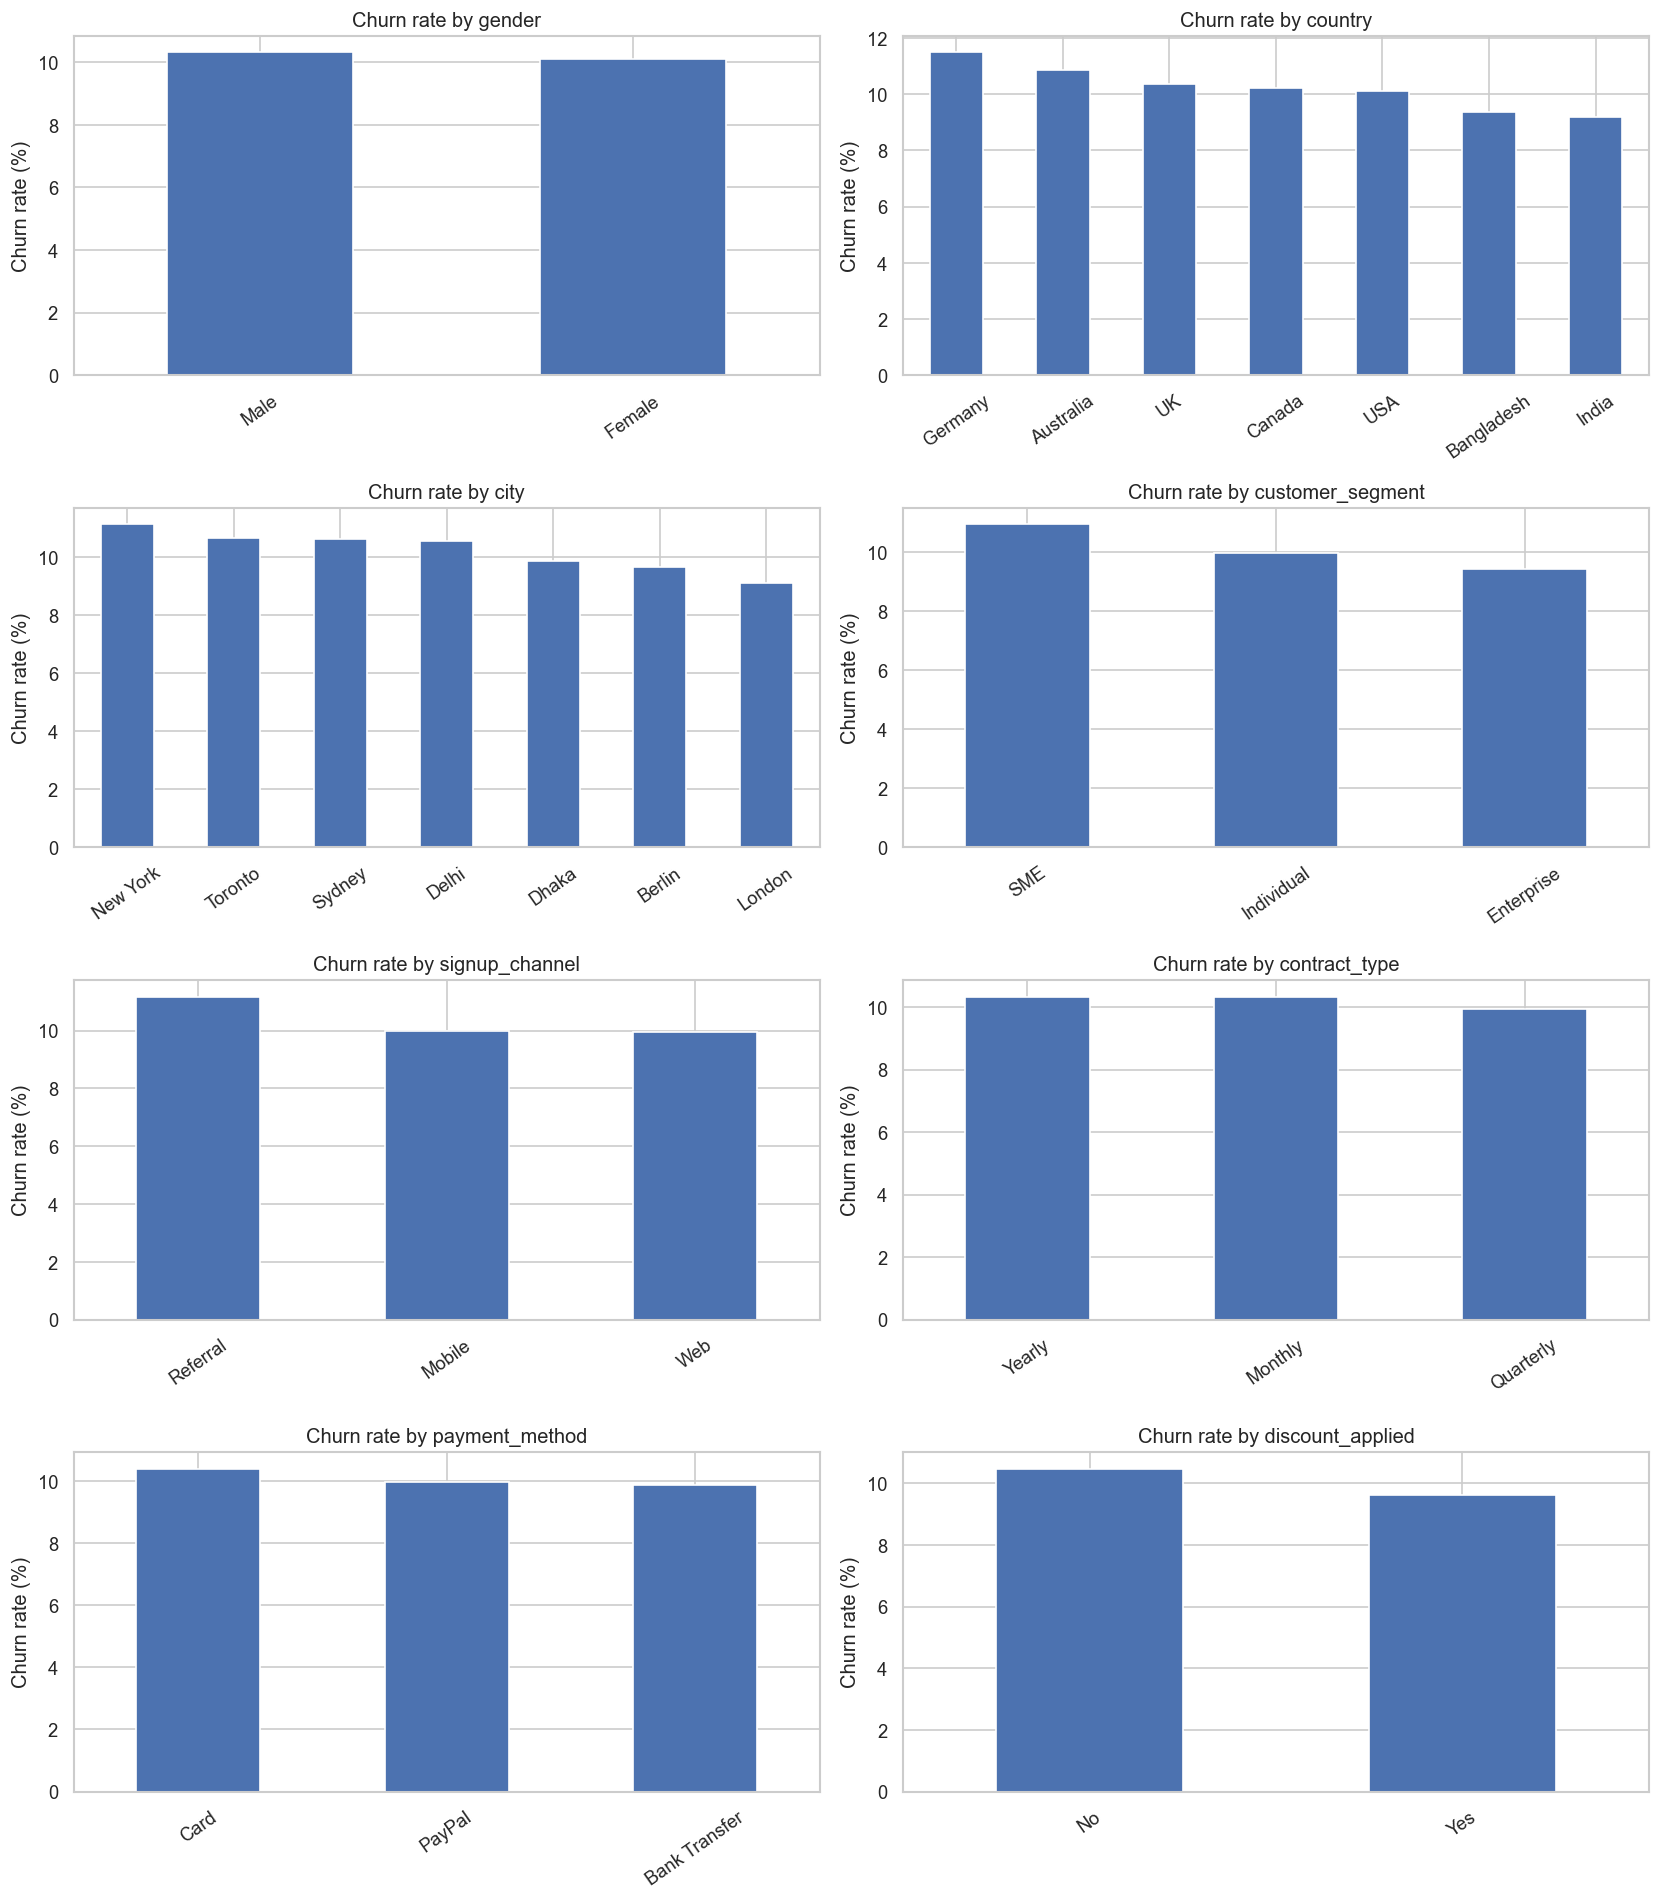

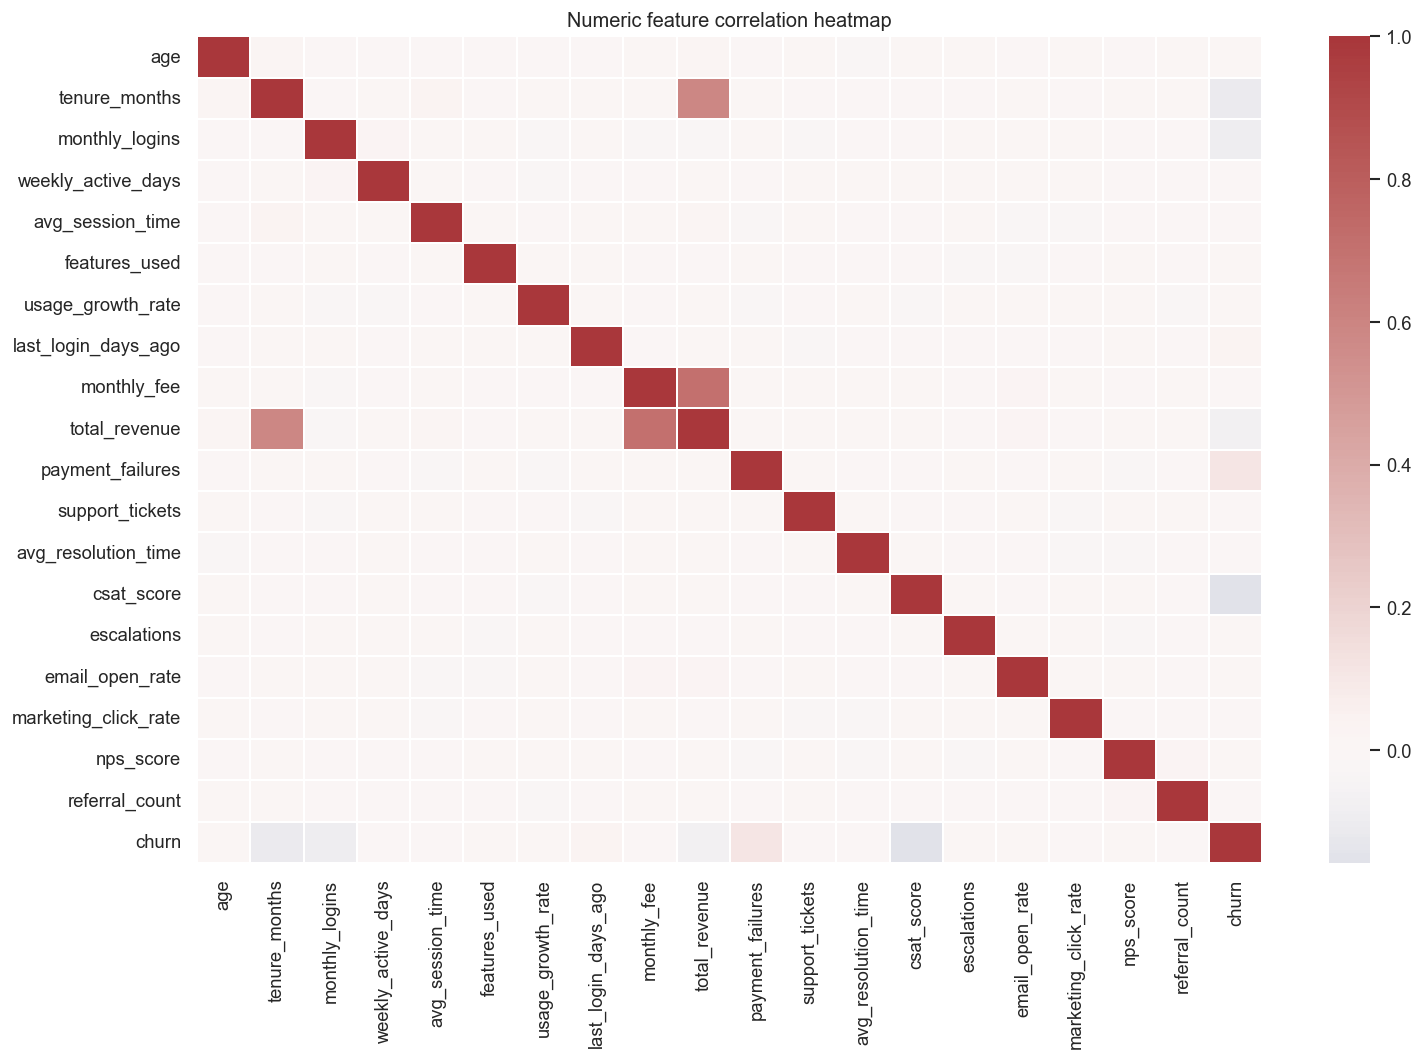

In [15]:
cat_cols_eda = [c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
                if c not in ID_COLUMNS + [TARGET]]
selected_cats = cat_cols_eda[:8]
if selected_cats:
    ncols = 2
    nrows = int(np.ceil(len(selected_cats) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, selected_cats):
        rates = (df.groupby(col, dropna=False)[TARGET].mean() * 100).sort_values(ascending=False).head(12)
        rates.plot(kind="bar", ax=ax)
        ax.set_title(f"Churn rate by {col}")
        ax.set_ylabel("Churn rate (%)")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=35)
    for ax in axes[len(selected_cats):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

corr_cols = df.select_dtypes(include=np.number).columns
if len(corr_cols) > 1:
    plt.figure(figsize=(13, 9))
    sns.heatmap(df[corr_cols].corr(), cmap="vlag", center=0, linewidths=0.2)
    plt.title("Numeric feature correlation heatmap")
    plt.tight_layout()
    plt.show()

## 4. Split data before fitting preprocessing

We use stratified train/validation/test subsets (70% / 15% / 15%). The training partition fits models and cross-validation tunes parameters; validation chooses the decision threshold; the test set is reserved for final reporting. Imputers and encoders live inside pipelines, so they are fitted separately within each CV fold.

We avoid applying SMOTE before splitting. Instead, class weights and XGBoost's `scale_pos_weight` address imbalance without synthetic rows crossing data boundaries.

In [16]:
X = df.drop(columns=[TARGET] + [c for c in ID_COLUMNS if c in df.columns]).copy()
y = df[TARGET].astype(int).copy()
assert TARGET not in X.columns and set(y.unique()).issubset({0, 1})

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.15 / 0.85,
    stratify=y_train_full, random_state=RANDOM_STATE
)
for label, target in [("Train", y_train), ("Validation", y_valid), ("Test", y_test)]:
    print(f"{label:10s}: {len(target):,} rows | churn rate {target.mean():.2%}")

Train     : 7,000 rows | churn rate 10.21%
Validation: 1,500 rows | churn rate 10.20%
Test      : 1,500 rows | churn rate 10.20%


## 5. Preprocessing and evaluation helpers

Categorical values use one-hot encoding rather than label encoding, which can incorrectly imply an order. Numeric values are median-imputed; Logistic Regression additionally scales numeric features. Metrics include ranking quality, class-specific performance, balanced accuracy, MCC, and probability quality.

In [17]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    categorical_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric_features),
        ("categorical", Pipeline(categorical_steps), categorical_features)
    ], remainder="drop")

def positive_probability(estimator, data):
    if hasattr(estimator, "predict_proba"):
        probs = estimator.predict_proba(data)
        model = estimator.named_steps["model"] if hasattr(estimator, "named_steps") else estimator
        class_index = list(model.classes_).index(1)
        return probs[:, class_index]
    return estimator.predict(data).astype(float)

def metric_row(name, truth, probabilities, threshold=0.5):
    probabilities = np.asarray(probabilities)
    predictions = (probabilities >= threshold).astype(int)
    clipped = np.clip(probabilities, 1e-7, 1 - 1e-7)
    return {
        "Model": name, "Threshold": threshold,
        "Accuracy": accuracy_score(truth, predictions),
        "Balanced accuracy": balanced_accuracy_score(truth, predictions),
        "Precision (churn)": precision_score(truth, predictions, zero_division=0),
        "Recall (churn)": recall_score(truth, predictions, zero_division=0),
        "F1 (churn)": f1_score(truth, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(truth, probabilities),
        "Average precision": average_precision_score(truth, probabilities),
        "MCC": matthews_corrcoef(truth, predictions),
        "Log loss": log_loss(truth, clipped, labels=[0, 1]),
        "Brier score": brier_score_loss(truth, probabilities)
    }

print(f"Numeric features: {len(numeric_features)} | categorical features: {len(categorical_features)}")

Numeric features: 19 | categorical features: 11


## 6. Fit candidate models

The majority-class dummy is a reference baseline. Logistic Regression is a linear baseline; Random Forest and Extra Trees capture nonlinear relationships. XGBoost is included when installed. Initial comparison uses validation data and a common threshold of 0.50.

In [19]:

models = {
    "Dummy baseline": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline([
        ("preprocess", make_preprocessor(True)),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=350, min_samples_leaf=2,
            class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ]),
    "Extra Trees": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", ExtraTreesClassifier(
            n_estimators=350, min_samples_leaf=2,
            class_weight="balanced",
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ])
}

if XGBOOST_AVAILABLE:
    models["XGBoost"] = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", XGBClassifier(
            n_estimators=350, max_depth=4, learning_rate=0.05,
            subsample=0.85, colsample_bytree=0.85, reg_lambda=2,
            min_child_weight=3, objective="binary:logistic",
            eval_metric="logloss",
            scale_pos_weight=(y_train == 0).sum() /
                             max((y_train == 1).sum(), 1),
            tree_method="hist", n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])

fitted_models, validation_probabilities, rows = {}, {}, []

for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    fitted_models[name] = estimator
    probabilities = positive_probability(estimator, X_valid)
    validation_probabilities[name] = probabilities
    rows.append(metric_row(name, y_valid, probabilities))

validation_results = (
    pd.DataFrame(rows)
    .sort_values("Average precision", ascending=False)
    .reset_index(drop=True)
)

numeric_columns = validation_results.select_dtypes(
    include=np.number
).columns

display(
    validation_results.style
    .format({col: "{:.3f}" for col in numeric_columns})
    .background_gradient(
        subset=["Average precision", "ROC-AUC", "F1 (churn)"],
        cmap="YlGn"
    )
    .set_properties(**{
        "text-align": "center",
        "padding": "8px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#202846"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [("border-bottom", "1px solid #dddddd")]
        }
    ])
)


,Model,Threshold,Accuracy,Balanced accuracy,Precision (churn),Recall (churn),F1 (churn),ROC-AUC,Average precision,MCC,Log loss,Brier score
0,XGBoost,0.500,0.794,0.735,0.282,0.660,0.395,0.828,0.346,0.333,0.384,0.123
1,Random Forest,0.500,0.896,0.499,0.000,0.000,0.000,0.833,0.330,-0.015,0.267,0.078
2,Extra Trees,0.500,0.898,0.500,0.000,0.000,0.000,0.794,0.292,0.000,0.305,0.085
3,Logistic Regression,0.500,0.683,0.696,0.201,0.712,0.314,0.760,0.253,0.247,0.594,0.204
4,Dummy baseline,0.500,0.898,0.500,0.000,0.000,0.000,0.500,0.102,0.000,1.644,0.102


## 7. Hyperparameter optimization

Randomized search uses stratified 3-fold cross-validation on the training data and optimizes **average precision**, which is informative for an imbalanced churn target. Search ranges balance model quality with practical run time. The validation and test partitions are not used for tuning.

In [20]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
if XGBOOST_AVAILABLE:
    tuning_name = "Tuned XGBoost"
    tuning_pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", XGBClassifier(
            objective="binary:logistic", eval_metric="logloss", tree_method="hist",
            scale_pos_weight=(y_train == 0).sum() / max((y_train == 1).sum(), 1),
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ])
    param_distributions = {
        "model__n_estimators": [200, 350, 500, 700],
        "model__max_depth": [2, 3, 4, 5, 6],
        "model__learning_rate": [0.02, 0.04, 0.06, 0.1],
        "model__min_child_weight": [1, 3, 5, 8],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0],
        "model__reg_lambda": [1, 2, 5, 10],
        "model__gamma": [0, 0.1, 0.3]
    }
else:
    tuning_name = "Tuned Extra Trees"
    tuning_pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", ExtraTreesClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
    ])
    param_distributions = {
        "model__n_estimators": [250, 400, 600],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": ["sqrt", 0.7, 1.0]
    }

search = RandomizedSearchCV(
    tuning_pipeline, param_distributions, n_iter=18, scoring="average_precision",
    cv=cv, n_jobs=-1, verbose=1, random_state=RANDOM_STATE,
    refit=True, return_train_score=True
)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Selected model:", tuning_name)
print(f"Best mean CV average precision: {search.best_score_:.4f}")
print("Best parameters:")
print(json.dumps(search.best_params_, indent=2))

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Selected model: Tuned XGBoost
Best mean CV average precision: 0.2777
Best parameters:
{
  "model__subsample": 0.7,
  "model__reg_lambda": 1,
  "model__n_estimators": 200,
  "model__min_child_weight": 5,
  "model__max_depth": 3,
  "model__learning_rate": 0.06,
  "model__gamma": 0.1,
  "model__colsample_bytree": 0.85
}


## 8. Select a classification threshold on validation data

The default probability cutoff of 0.50 is not always best for churn detection. We choose the threshold that maximizes validation F1, then freeze it before the final test. A business deployment should instead select a threshold based on outreach cost, missed churn cost, and intervention effectiveness.

Validation-selected threshold: 0.550


,threshold,precision,recall,f1
100,0.550,0.287,0.758,0.417


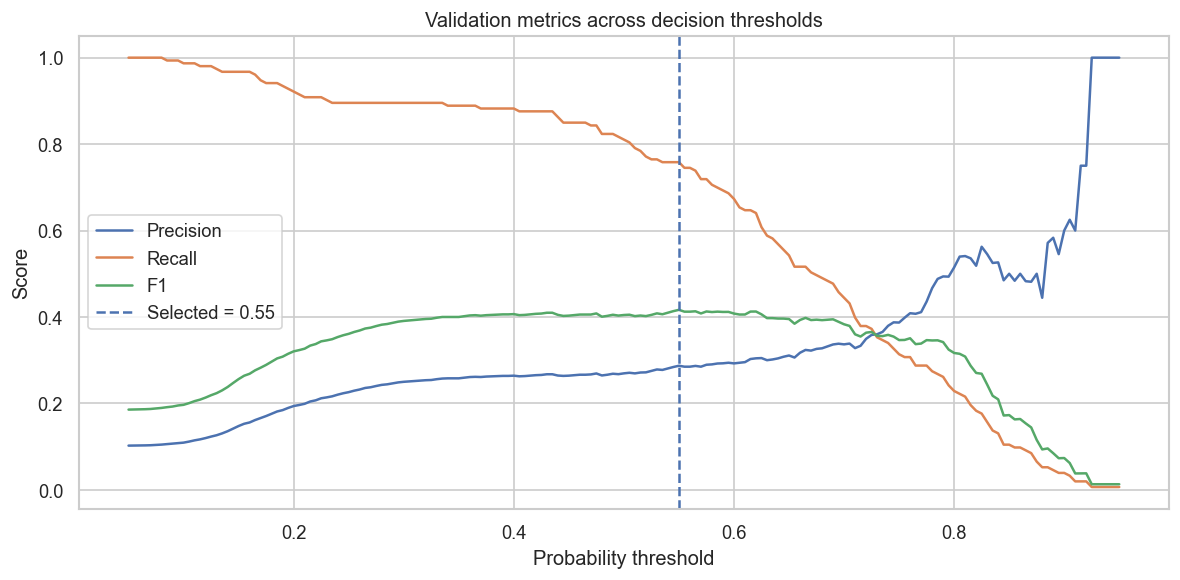

In [21]:
best_valid_prob = positive_probability(best_model, X_valid)
threshold_grid = np.linspace(0.05, 0.95, 181)
threshold_rows = []
for threshold in threshold_grid:
    predicted = (best_valid_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_valid, predicted, zero_division=0),
        "recall": recall_score(y_valid, predicted, zero_division=0),
        "f1": f1_score(y_valid, predicted, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_rows)
best_threshold = float(threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"])
print(f"Validation-selected threshold: {best_threshold:.3f}")
display(threshold_df.loc[[threshold_df["f1"].idxmax()]].style.format("{:.3f}"))

plt.figure(figsize=(10, 5))
for metric in ["precision", "recall", "f1"]:
    plt.plot(threshold_df["threshold"], threshold_df[metric], label=metric.title())
plt.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.2f}")
plt.title("Validation metrics across decision thresholds")
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Final test-set evaluation

The test set is evaluated only after the model and threshold are selected. Accuracy alone can hide poor minority-class performance, so we report precision, recall, F1, ROC-AUC, average precision, balanced accuracy, MCC, log loss, and Brier score.

In [22]:
test_prob = positive_probability(best_model, X_test)
test_pred = (test_prob >= best_threshold).astype(int)
final_metrics = pd.DataFrame([
    metric_row("Tuned model @ 0.50", y_test, test_prob, 0.50),
    metric_row(f"Tuned model @ {best_threshold:.2f}", y_test, test_prob, best_threshold)
])
print("FINAL TEST METRICS")
display(final_metrics.style.format({
    c: "{:.3f}" for c in final_metrics.select_dtypes(include=np.number).columns
}).background_gradient(subset=["Average precision", "ROC-AUC", "F1 (churn)"], cmap="YlGn"))

print("\\nClassification report at the validation-selected threshold")
print(classification_report(y_test, test_pred, target_names=["Retained (0)", "Churned (1)"], digits=3, zero_division=0))

FINAL TEST METRICS


,Model,Threshold,Accuracy,Balanced accuracy,Precision (churn),Recall (churn),F1 (churn),ROC-AUC,Average precision,MCC,Log loss,Brier score
0,Tuned model @ 0.50,0.500,0.744,0.739,0.246,0.732,0.368,0.784,0.290,0.314,0.475,0.156
1,Tuned model @ 0.55,0.550,0.765,0.727,0.256,0.680,0.371,0.784,0.290,0.310,0.475,0.156


\nClassification report at the validation-selected threshold
              precision    recall  f1-score   support

Retained (0)      0.955     0.775     0.856      1347
 Churned (1)      0.256     0.680     0.371       153

    accuracy                          0.765      1500
   macro avg      0.605     0.727     0.614      1500
weighted avg      0.884     0.765     0.806      1500



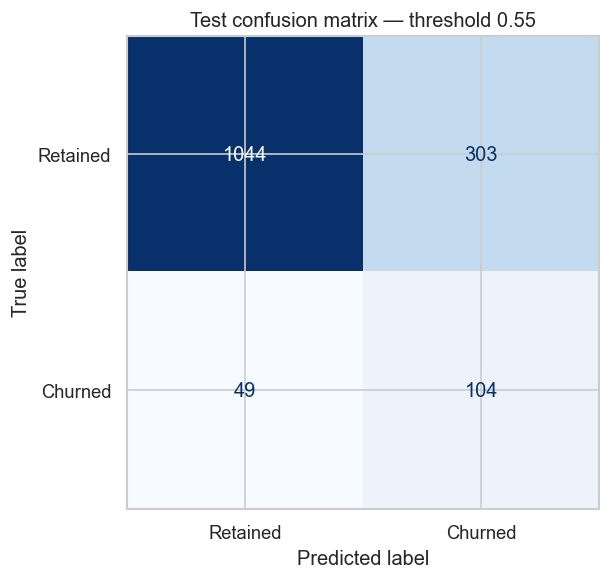

Business-facing summary
  Churners detected: 104 / 153 (68.0% recall)
  False-positive alerts: 303
  Missed churners: 49
  Correctly unflagged retained customers: 1,044


In [23]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Retained", "Churned"]).plot(
    cmap="Blues", values_format="d", colorbar=False
)
plt.title(f"Test confusion matrix — threshold {best_threshold:.2f}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print("Business-facing summary")
print(f"  Churners detected: {tp:,} / {tp + fn:,} ({tp / max(tp + fn, 1):.1%} recall)")
print(f"  False-positive alerts: {fp:,}")
print(f"  Missed churners: {fn:,}")
print(f"  Correctly unflagged retained customers: {tn:,}")

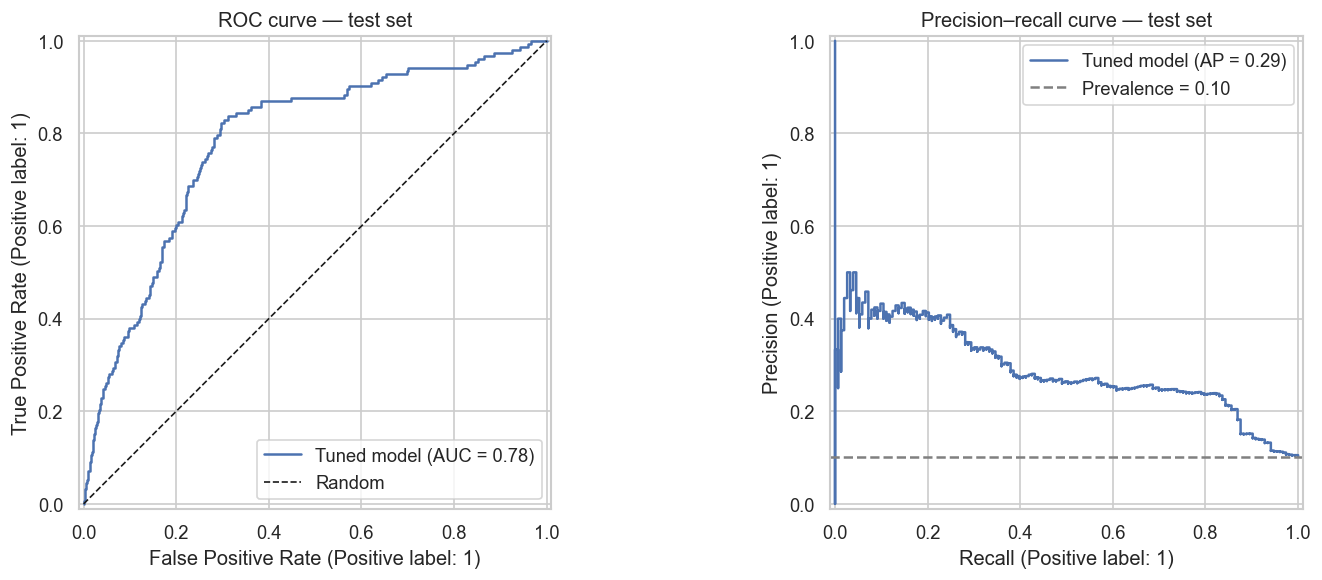

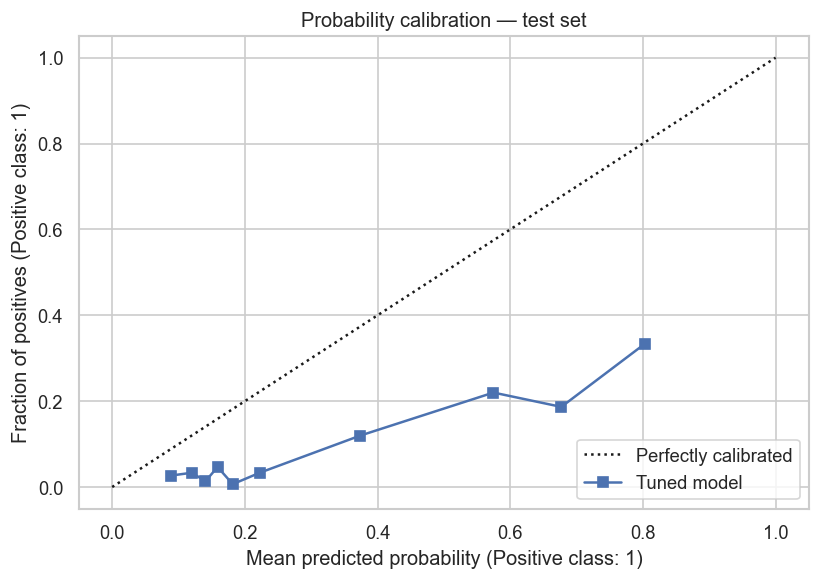

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[0], name="Tuned model")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random")
axes[0].set_title("ROC curve — test set")
axes[0].legend()
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[1], name="Tuned model")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label=f"Prevalence = {y_test.mean():.2f}")
axes[1].set_title("Precision–recall curve — test set")
axes[1].legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
CalibrationDisplay.from_predictions(y_test, test_prob, n_bins=10, strategy="quantile", ax=ax, name="Tuned model")
ax.set_title("Probability calibration — test set")
plt.tight_layout()
plt.show()

## 10. Candidate comparison and visualizations

The model comparison below uses validation data and a shared threshold of 0.50. The tuned model is also shown at its validation-selected threshold. These comparisons help explain model trade-offs without repeatedly using the test set for selection.

,Model,Threshold,Accuracy,Balanced accuracy,Precision (churn),Recall (churn),F1 (churn),ROC-AUC,Average precision,MCC,Log loss,Brier score
5,Tuned XGBoost,0.550,0.783,0.772,0.287,0.758,0.417,0.837,0.364,0.371,0.450,0.146
4,XGBoost,0.500,0.794,0.735,0.282,0.660,0.395,0.828,0.346,0.333,0.384,0.123
2,Random Forest,0.500,0.896,0.499,0.000,0.000,0.000,0.833,0.330,-0.015,0.267,0.078
3,Extra Trees,0.500,0.898,0.500,0.000,0.000,0.000,0.794,0.292,0.000,0.305,0.085
1,Logistic Regression,0.500,0.683,0.696,0.201,0.712,0.314,0.760,0.253,0.247,0.594,0.204
0,Dummy baseline,0.500,0.898,0.500,0.000,0.000,0.000,0.500,0.102,0.000,1.644,0.102


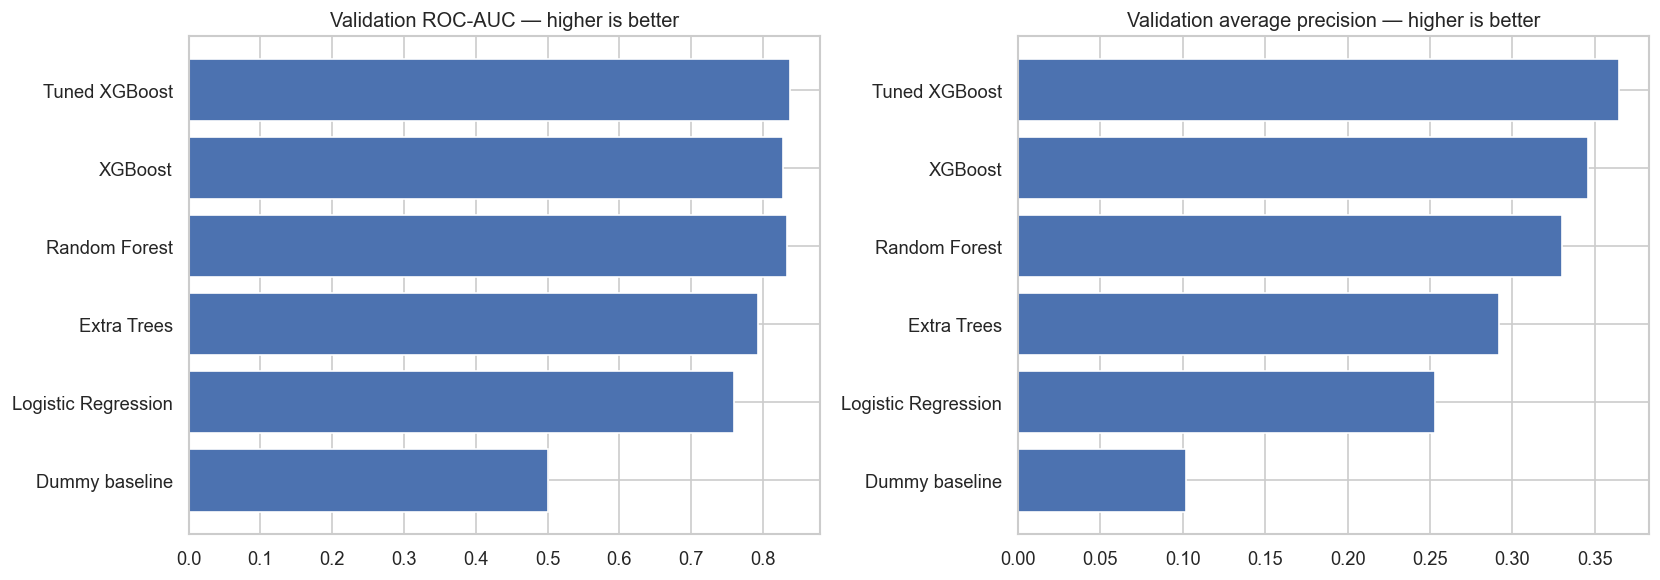

In [25]:
comparison_rows = [metric_row(name, y_valid, probs, 0.50)
                   for name, probs in validation_probabilities.items()]
comparison_rows.append(metric_row(tuning_name, y_valid, best_valid_prob, best_threshold))
comparison_df = pd.DataFrame(comparison_rows).sort_values("Average precision", ascending=False)
display(comparison_df.style.format({
    c: "{:.3f}" for c in comparison_df.select_dtypes(include=np.number).columns
}))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(comparison_df["Model"], comparison_df["ROC-AUC"])
axes[0].invert_yaxis()
axes[0].set_title("Validation ROC-AUC — higher is better")
axes[1].barh(comparison_df["Model"], comparison_df["Average precision"])
axes[1].invert_yaxis()
axes[1].set_title("Validation average precision — higher is better")
plt.tight_layout()
plt.show()

## 11. Feature importance with permutation testing

Permutation importance measures how much average precision falls when a feature is shuffled. It is model-agnostic and avoids some biases of tree impurity importance. This is a global diagnostic, not proof that a feature causes churn.

,feature,importance_mean,importance_std
5,tenure_months,0.0898,0.0137
8,monthly_logins,0.0613,0.0053
23,csat_score,0.0604,0.0097
17,payment_failures,0.0374,0.0057
13,last_login_days_ago,0.0065,0.0071
12,usage_growth_rate,0.0049,0.0012
2,country,0.0039,0.0014
7,contract_type,0.0035,0.0022
9,weekly_active_days,0.0026,0.0017
29,referral_count,0.0025,0.0013


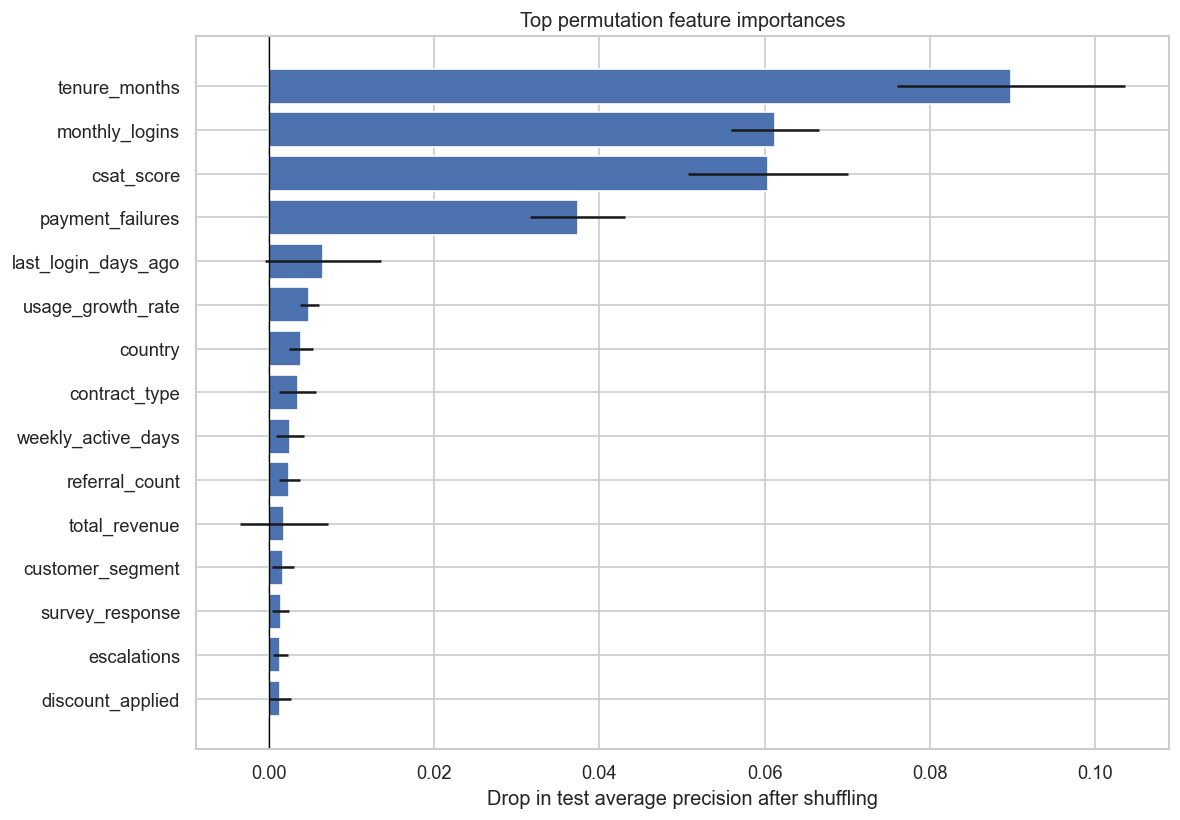

In [26]:
perm = permutation_importance(
    best_model, X_test, y_test, scoring="average_precision",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance.head(20).style.format({
    "importance_mean": "{:.4f}", "importance_std": "{:.4f}"
}))
top = importance.head(15).sort_values("importance_mean")
plt.figure(figsize=(10, 7))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Drop in test average precision after shuffling")
plt.title("Top permutation feature importances")
plt.tight_layout()
plt.show()

## 12. Error analysis

False negatives are churners the model missed; false positives are retained customers flagged as at risk. Reviewing these rows can reveal data quality issues or operational opportunities. Do not publish customer-level rows if the data is sensitive.

In [27]:
errors = X_test.copy()
errors["actual_churn"] = y_test
errors["predicted_churn"] = test_pred
errors["predicted_probability"] = test_prob
errors["error_type"] = np.select([
    (errors["actual_churn"] == 1) & (errors["predicted_churn"] == 0),
    (errors["actual_churn"] == 0) & (errors["predicted_churn"] == 1)
], ["False negative — missed churner", "False positive — unnecessary alert"], default="Correct")
display(errors[errors["error_type"] != "Correct"].head(20))
display(errors["error_type"].value_counts().rename("count").to_frame())

,gender,age,country,city,customer_segment,tenure_months,signup_channel,contract_type,monthly_logins,weekly_active_days,avg_session_time,features_used,usage_growth_rate,last_login_days_ago,monthly_fee,total_revenue,payment_method,payment_failures,discount_applied,price_increase_last_3m,support_tickets,avg_resolution_time,complaint_type,csat_score,escalations,email_open_rate,marketing_click_rate,nps_score,survey_response,referral_count,actual_churn,predicted_churn,predicted_probability,error_type
7735,Female,18,Germany,Sydney,SME,23,Web,Yearly,22,1,7.212315,6,0.32,1,10,230,PayPal,0,No,No,1,29.317554,Technical,2.0,1,0.55,0.37,-7,Neutral,0,0,1,0.650206,False positive — unnecessary alert
5326,Male,46,Canada,London,SME,37,Mobile,Quarterly,8,3,13.104492,5,-0.12,14,10,370,Card,0,No,No,2,15.139570,NaN,2.0,1,0.16,0.24,70,Satisfied,1,0,1,0.714438,False positive — unnecessary alert
5482,Male,34,Canada,Dhaka,Individual,2,Web,Quarterly,16,1,17.663109,6,0.04,8,20,40,Card,0,No,No,2,34.755593,Billing,3.0,1,0.67,0.13,2,Satisfied,1,0,1,0.740828,False positive — unnecessary alert
7380,Female,61,Australia,Toronto,Individual,42,Referral,Monthly,21,2,8.209216,2,0.15,15,70,2940,Card,2,No,No,2,20.983217,Billing,3.0,0,0.71,0.16,15,Satisfied,1,0,1,0.679751,False positive — unnecessary alert
3083,Male,18,Bangladesh,New York,SME,33,Web,Quarterly,16,7,21.280178,2,-0.06,29,30,990,Card,0,No,No,2,22.384207,NaN,3.0,1,0.24,0.24,-3,Satisfied,1,1,0,0.201865,False negative — missed churner
9191,Female,52,Germany,London,Enterprise,31,Web,Monthly,42,0,20.696284,5,0.18,2,10,310,Card,0,Yes,Yes,2,22.592912,Technical,2.0,0,0.88,0.19,68,Satisfied,0,0,1,0.721147,False positive — unnecessary alert
2627,Female,40,Germany,Toronto,SME,1,Referral,Yearly,24,5,7.618731,5,-0.09,3,20,20,Card,0,Yes,No,2,24.357644,NaN,4.0,0,0.71,0.40,37,Satisfied,1,0,1,0.762277,False positive — unnecessary alert
2962,Female,57,Canada,Dhaka,Individual,46,Referral,Quarterly,10,4,19.660602,3,-0.09,6,50,2300,Card,0,No,No,3,17.227926,Technical,2.0,0,0.57,0.40,53,Neutral,0,0,1,0.688789,False positive — unnecessary alert
4444,Female,41,India,Dhaka,Enterprise,2,Referral,Quarterly,28,1,15.075890,6,0.15,0,50,100,Card,1,No,No,2,9.874553,Billing,3.0,0,0.60,0.20,92,Satisfied,2,0,1,0.634351,False positive — unnecessary alert
1054,Male,38,UK,London,Individual,27,Mobile,Monthly,24,5,1.000000,4,0.09,2,30,810,Card,0,Yes,No,0,38.130990,Billing,2.0,0,0.86,0.17,51,Satisfied,2,0,1,0.609218,False positive — unnecessary alert


,count
error_type,
Correct,1148
False positive — unnecessary alert,303
False negative — missed churner,49


## 13. Save model and evaluation artifacts

The preprocessing steps and classifier are saved together as one pipeline. This avoids accidentally applying a different encoder or scaler at inference time. The JSON report records the threshold and metrics generated by the current run.

In [28]:
model_path = OUTPUT_DIR / "customer_churn_pipeline.joblib"
metrics_path = OUTPUT_DIR / "test_metrics.json"
importance_path = OUTPUT_DIR / "permutation_importance.csv"
comparison_path = OUTPUT_DIR / "validation_model_comparison.csv"

joblib.dump(best_model, model_path)
importance.to_csv(importance_path, index=False)
comparison_df.to_csv(comparison_path, index=False)

def json_safe(value):
    if isinstance(value, (np.integer,)): return int(value)
    if isinstance(value, (np.floating,)): return float(value)
    if isinstance(value, (np.bool_,)): return bool(value)
    if isinstance(value, dict): return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, list): return [json_safe(v) for v in value]
    return value

report = {
    "selected_model": tuning_name,
    "decision_threshold": best_threshold,
    "best_mean_cv_average_precision": float(search.best_score_),
    "best_parameters": search.best_params_,
    "test_metrics_at_selected_threshold": final_metrics.iloc[1].to_dict(),
    "feature_columns": X.columns.tolist(),
    "target": TARGET,
    "random_state": RANDOM_STATE
}
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(json_safe(report), f, indent=2)

print("Artifacts saved:")
for path in [model_path, metrics_path, importance_path, comparison_path]:
    print(" •", path)

Artifacts saved:
 • artifacts\customer_churn_pipeline.joblib
 • artifacts\test_metrics.json
 • artifacts\permutation_importance.csv
 • artifacts\validation_model_comparison.csv


## 14. Inference smoke test

Reload the saved artifact and check that it produces finite probabilities between 0 and 1 for a small batch. This validates the serialization/inference path, but it does not replace external validation or production monitoring.

In [29]:
reloaded_model = joblib.load(model_path)
sample = X_test.head(5)
sample_prob = positive_probability(reloaded_model, sample)
assert len(sample_prob) == len(sample)
assert np.isfinite(sample_prob).all()
assert ((sample_prob >= 0) & (sample_prob <= 1)).all()

sample_output = sample.copy()
sample_output["predicted_churn_probability"] = sample_prob
sample_output["predicted_churn"] = (sample_prob >= best_threshold).astype(int)
display(sample_output)
print("PASS: model reload and inference smoke test.")

,gender,age,country,city,customer_segment,tenure_months,signup_channel,contract_type,monthly_logins,weekly_active_days,avg_session_time,features_used,usage_growth_rate,last_login_days_ago,monthly_fee,total_revenue,payment_method,payment_failures,discount_applied,price_increase_last_3m,support_tickets,avg_resolution_time,complaint_type,csat_score,escalations,email_open_rate,marketing_click_rate,nps_score,survey_response,referral_count,predicted_churn_probability,predicted_churn
1924,Female,52,Canada,Delhi,Individual,16,Referral,Quarterly,25,1,11.897561,3,0.04,1,20,320,Card,0,Yes,No,2,22.313086,Billing,4.0,0,0.17,0.15,19,Unsatisfied,0,0.112707,0
3094,Male,50,Germany,London,Individual,50,Web,Monthly,34,5,16.689102,2,-0.29,30,70,3500,Card,0,No,No,2,17.301560,NaN,2.0,0,0.59,0.05,77,Neutral,1,0.421403,0
3957,Male,44,USA,London,SME,12,Web,Monthly,25,7,1.000000,2,0.08,1,30,360,PayPal,1,No,Yes,2,35.615087,Technical,3.0,2,0.69,0.42,28,Satisfied,1,0.167773,0
4181,Male,71,Bangladesh,Dhaka,SME,6,Web,Yearly,36,5,30.793498,6,0.12,12,20,120,Card,0,Yes,Yes,0,24.299696,Service,3.0,0,0.67,0.15,63,Unsatisfied,0,0.150128,0
7735,Female,18,Germany,Sydney,SME,23,Web,Yearly,22,1,7.212315,6,0.32,1,10,230,PayPal,0,No,No,1,29.317554,Technical,2.0,1,0.55,0.37,-7,Neutral,0,0.650206,1


PASS: model reload and inference smoke test.


## 15. Conclusions and responsible next steps

- Use precision/recall trade-offs and business costs to choose a deployment threshold.
- Validate on a future-period holdout if timestamped data becomes available.
- Confirm every predictor is available **before** the churn decision; remove post-outcome or leakage-prone columns.
- Monitor churn prevalence, feature drift, calibration, and retention campaign outcomes.
- Treat feature importance as association, not causation.
- Check the dataset license and privacy requirements before publishing the CSV, customer examples, or model artifacts to GitHub.

## 16. Advanced visual analytics dashboard

This section adds a more polished visual story: churn-rate by customer segments, model scorecards, threshold trade-offs, lift/gains, probability distributions, and an at-a-glance performance dashboard. These charts are generated from the current dataset and fitted model; they do not use hard-coded metrics.

,Metric,Score
0,Accuracy,0.765
1,Balanced accuracy,0.727
2,Precision,0.256
3,Recall,0.680
4,F1 score,0.371
5,ROC-AUC,0.784
6,Average precision,0.290
7,MCC,0.310


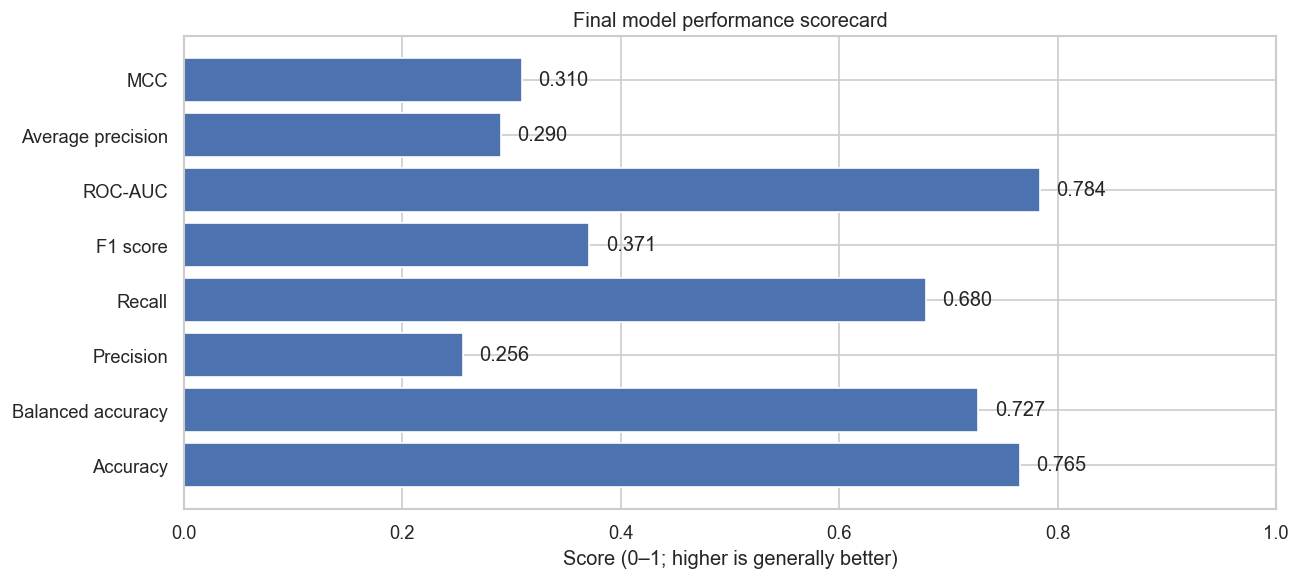

In [30]:
# 16.1 Model scorecard: compare the final model's key test metrics.
# All values are computed from the current run.
selected_test_row = final_metrics.iloc[1].copy()
scorecard_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1 score": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob),
    "Average precision": average_precision_score(y_test, test_prob),
    "MCC": matthews_corrcoef(y_test, test_pred)
}
scorecard = pd.DataFrame({"Metric": list(scorecard_metrics.keys()),
                          "Score": list(scorecard_metrics.values())})
display(scorecard.style.format({"Score": "{:.3f}"}).background_gradient(subset=["Score"], cmap="viridis"))

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(scorecard["Metric"], scorecard["Score"])
ax.set_xlim(0, 1)
ax.set_xlabel("Score (0–1; higher is generally better)")
ax.set_title("Final model performance scorecard")
for bar, value in zip(bars, scorecard["Score"]):
    ax.text(min(value + 0.015, 0.96), bar.get_y() + bar.get_height()/2, f"{value:.3f}", va="center")
plt.tight_layout()
plt.show()

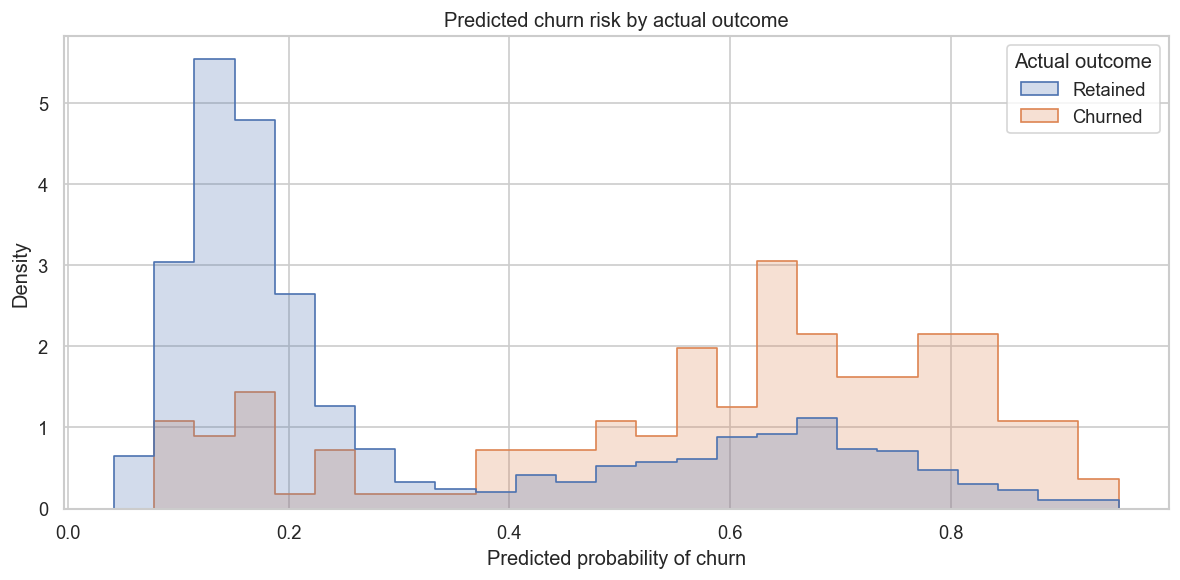

In [31]:
# 16.2 Probability distribution: do predicted risks separate actual churners?
risk_frame = pd.DataFrame({
    "Actual outcome": np.where(np.asarray(y_test) == 1, "Churned", "Retained"),
    "Predicted churn probability": test_prob
})
plt.figure(figsize=(10, 5))
sns.histplot(
    data=risk_frame, x="Predicted churn probability", hue="Actual outcome",
    bins=25, stat="density", common_norm=False, element="step", fill=True, alpha=0.25
)
plt.title("Predicted churn risk by actual outcome")
plt.xlabel("Predicted probability of churn")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

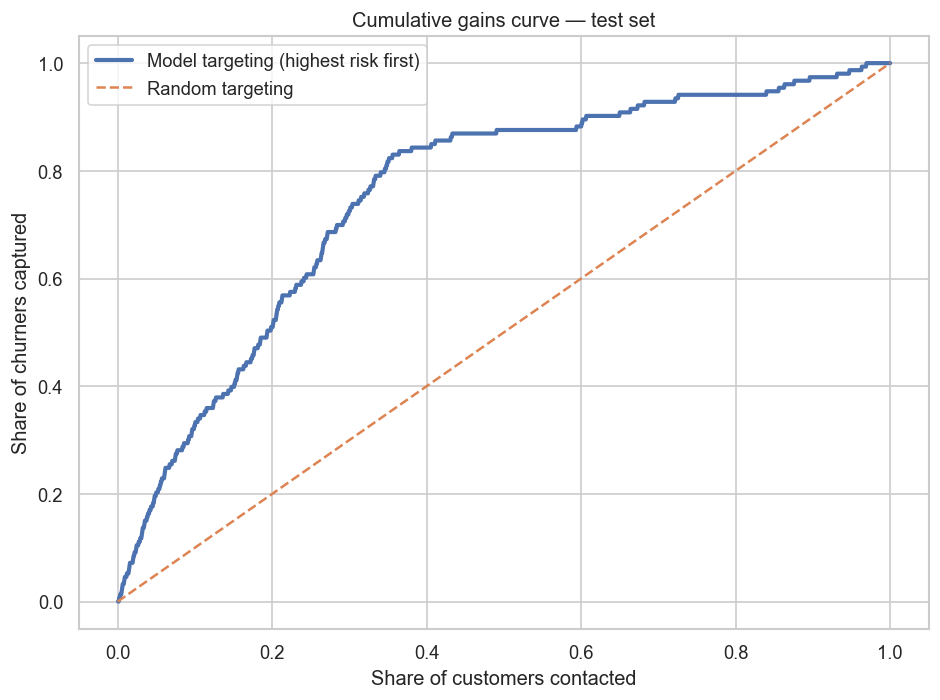

,risk_decile,customers,churn_rate,mean_predicted_risk,lift_vs_baseline
0,Decile 1,150,33.33%,80.26%,3.27x
1,Decile 2,150,18.67%,67.69%,1.83x
2,Decile 3,150,22.00%,57.47%,2.16x
3,Decile 4,150,12.00%,37.43%,1.18x
4,Decile 5,150,3.33%,22.25%,0.33x
5,Decile 6,150,0.67%,18.17%,0.07x
6,Decile 7,150,4.67%,15.89%,0.46x
7,Decile 8,150,1.33%,14.05%,0.13x
8,Decile 9,150,3.33%,12.02%,0.33x
9,Decile 10,150,2.67%,8.86%,0.26x


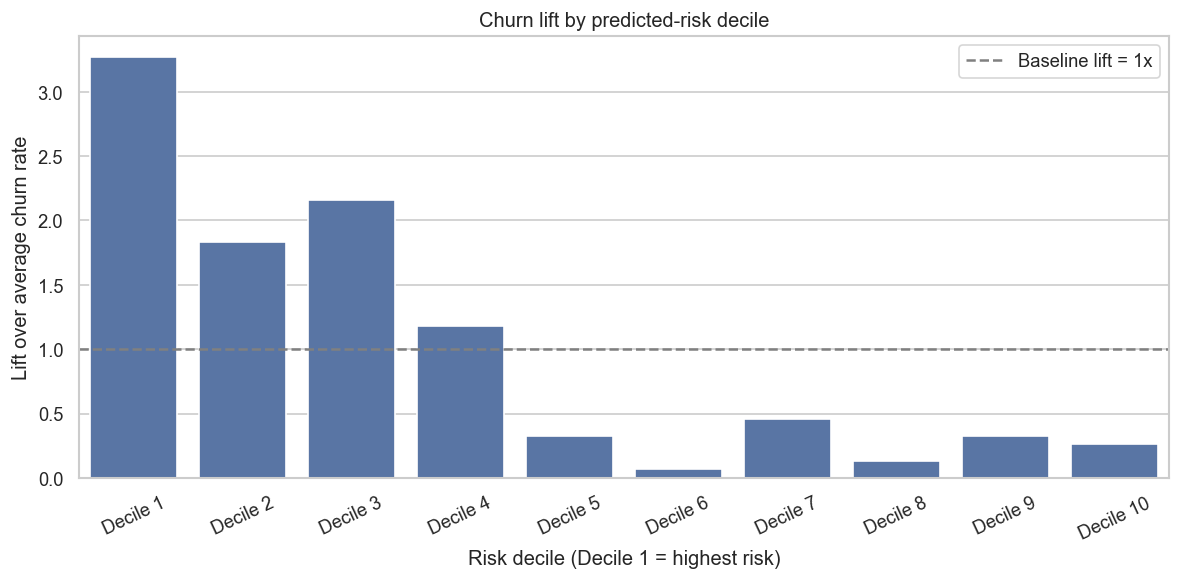

In [32]:
# 16.3 Cumulative gains / lift chart: how many churners are found by targeting the riskiest customers?
gain_df = pd.DataFrame({"actual": np.asarray(y_test), "probability": test_prob})
gain_df = gain_df.sort_values("probability", ascending=False).reset_index(drop=True)
gain_df["customer_fraction"] = (np.arange(len(gain_df)) + 1) / len(gain_df)
gain_df["cumulative_churn_fraction"] = gain_df["actual"].cumsum() / max(gain_df["actual"].sum(), 1)

plt.figure(figsize=(8, 6))
plt.plot(gain_df["customer_fraction"], gain_df["cumulative_churn_fraction"],
         label="Model targeting (highest risk first)", linewidth=2.5)
plt.plot([0, 1], [0, 1], "--", label="Random targeting")
plt.xlabel("Share of customers contacted")
plt.ylabel("Share of churners captured")
plt.title("Cumulative gains curve — test set")
plt.legend()
plt.tight_layout()
plt.show()

# Lift by decile: top decile means the 10% of customers assigned the highest risk.
gain_df["risk_decile"] = pd.qcut(
    gain_df["probability"].rank(method="first", ascending=False),
    q=10, labels=[f"Decile {i}" for i in range(1, 11)]
)
decile = gain_df.groupby("risk_decile", observed=False).agg(
    customers=("actual", "size"), churn_rate=("actual", "mean"),
    mean_predicted_risk=("probability", "mean")
).reset_index()
base_rate = gain_df["actual"].mean()
decile["lift_vs_baseline"] = decile["churn_rate"] / max(base_rate, 1e-9)
display(decile.style.format({
    "churn_rate": "{:.2%}", "mean_predicted_risk": "{:.2%}", "lift_vs_baseline": "{:.2f}x"
}))
plt.figure(figsize=(10, 5))
sns.barplot(data=decile, x="risk_decile", y="lift_vs_baseline")
plt.axhline(1, linestyle="--", color="gray", label="Baseline lift = 1x")
plt.title("Churn lift by predicted-risk decile")
plt.xlabel("Risk decile (Decile 1 = highest risk)")
plt.ylabel("Lift over average churn rate")
plt.xticks(rotation=25)
plt.legend()
plt.tight_layout()
plt.show()

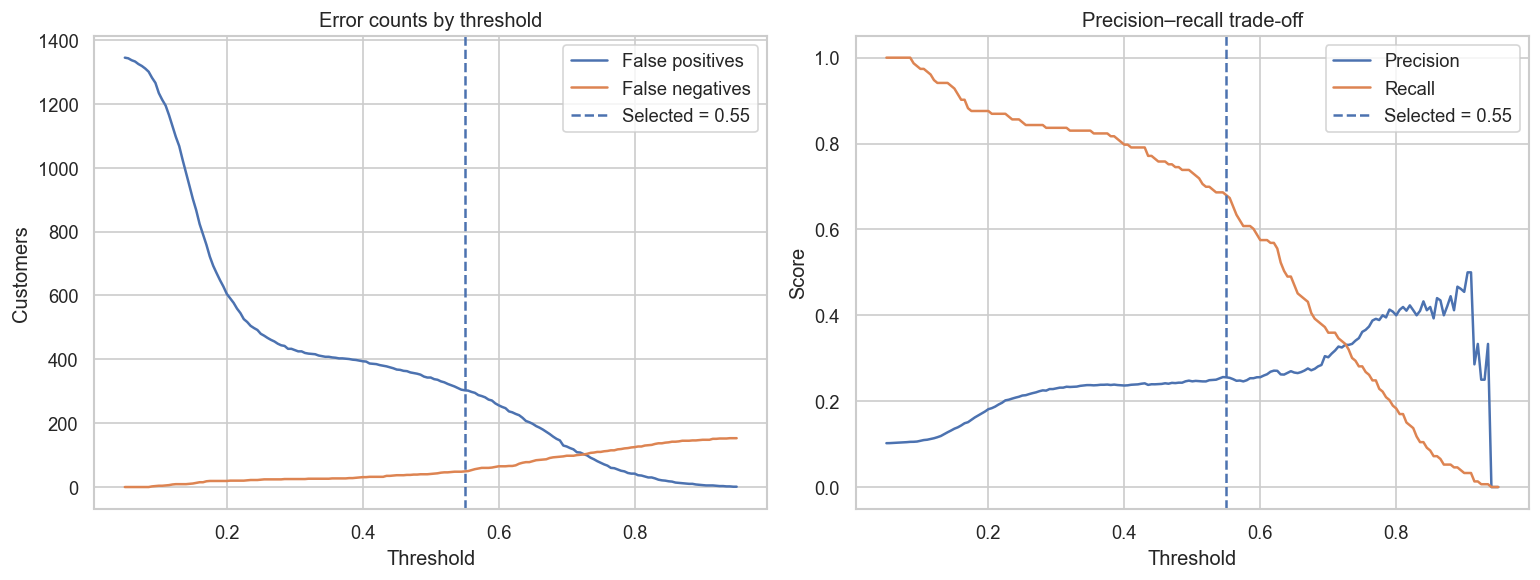

In [33]:
# 16.4 Threshold trade-off: false positives and false negatives as threshold changes.
threshold_errors = []
for threshold in threshold_grid:
    pred = (test_prob >= threshold).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    threshold_errors.append({
        "threshold": threshold, "false_positives": fp_, "false_negatives": fn_,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0)
    })
threshold_error_df = pd.DataFrame(threshold_errors)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(threshold_error_df["threshold"], threshold_error_df["false_positives"], label="False positives")
axes[0].plot(threshold_error_df["threshold"], threshold_error_df["false_negatives"], label="False negatives")
axes[0].axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.2f}")
axes[0].set_title("Error counts by threshold")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Customers")
axes[0].legend()
axes[1].plot(threshold_error_df["threshold"], threshold_error_df["precision"], label="Precision")
axes[1].plot(threshold_error_df["threshold"], threshold_error_df["recall"], label="Recall")
axes[1].axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.2f}")
axes[1].set_title("Precision–recall trade-off")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Score")
axes[1].legend()
plt.tight_layout()
plt.show()

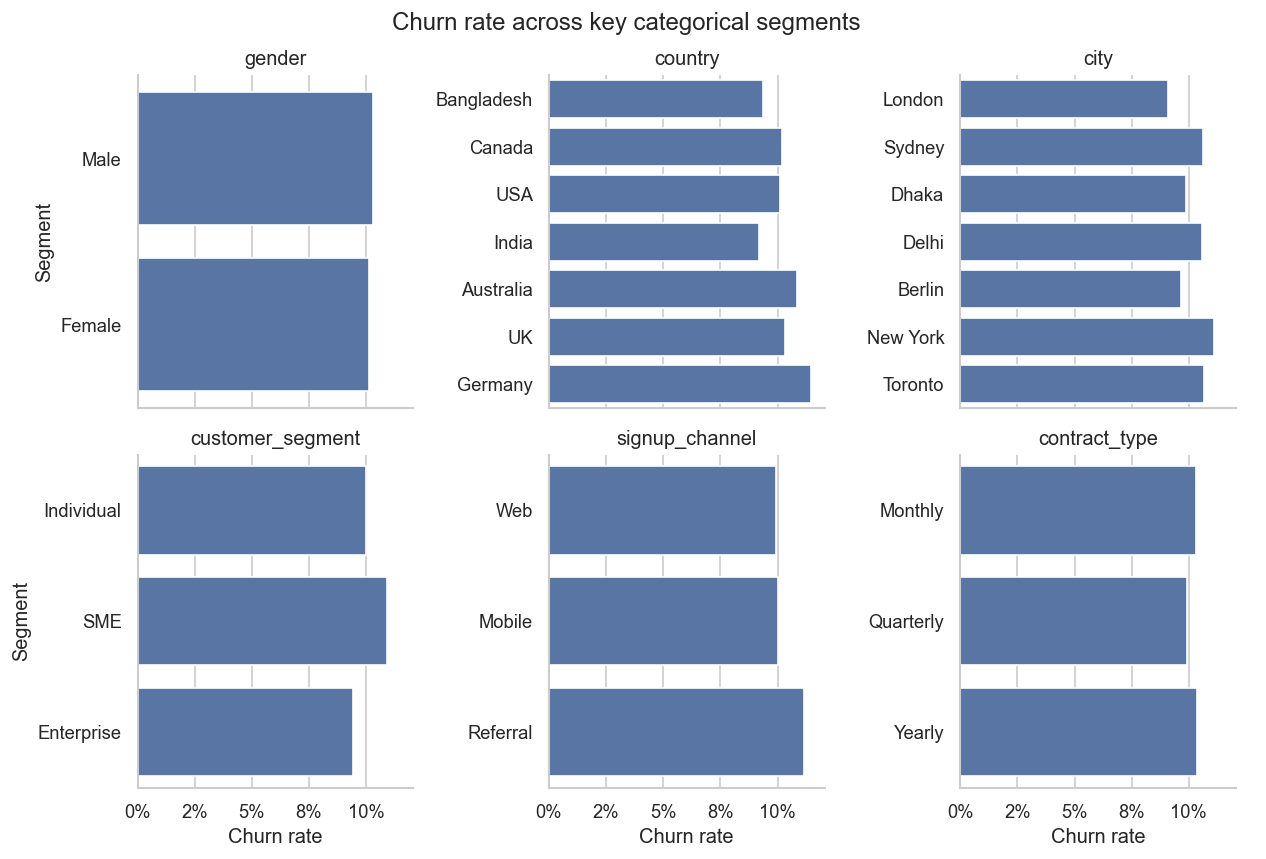

In [34]:
# 16.5 Segment-level churn dashboard for the most informative categorical fields.
# Display top categories by sample size to avoid unstable percentages from tiny groups.
segment_cols = [
    c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
    if c not in ID_COLUMNS + [TARGET]
][:6]
if segment_cols:
    segment_rows = []
    for col in segment_cols:
        temp = df.groupby(col, dropna=False)[TARGET].agg(["mean", "count"]).reset_index()
        temp.columns = ["segment", "churn_rate", "customers"]
        temp["feature"] = col
        temp = temp.sort_values("customers", ascending=False).head(8)
        segment_rows.append(temp)
    segment_summary = pd.concat(segment_rows, ignore_index=True)
    g = sns.catplot(
        data=segment_summary, x="churn_rate", y="segment", col="feature",
        col_wrap=3, kind="bar", sharex=True, sharey=False, height=3.5
    )
    g.set_axis_labels("Churn rate", "Segment")
    g.set_titles("{col_name}")
    g.fig.suptitle("Churn rate across key categorical segments", y=1.02)
    for ax in g.axes.flat:
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    plt.show()
else:
    print("No categorical columns available for segment-level plots.")

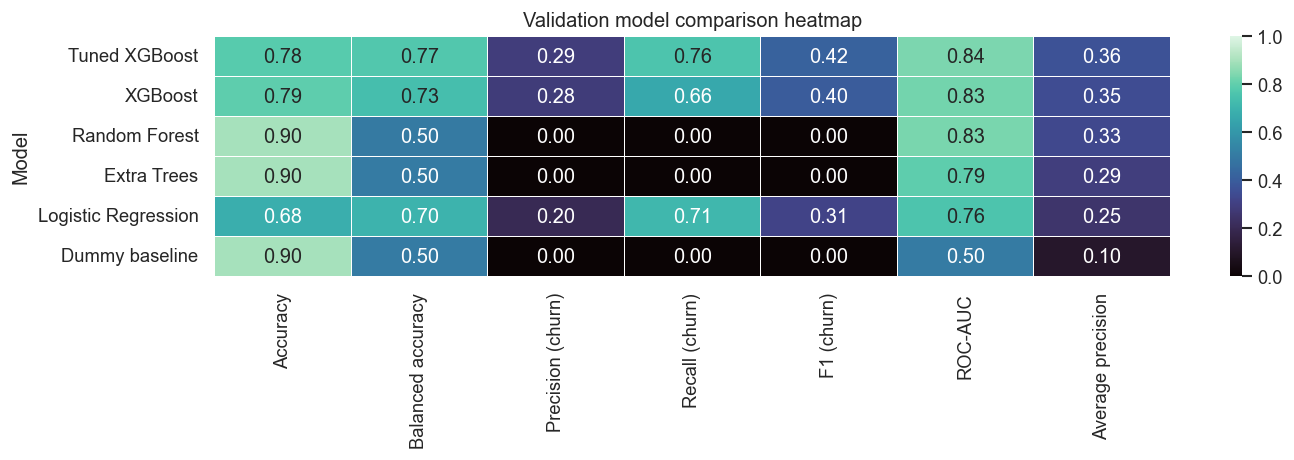

In [35]:
# 16.6 Correlation-style view of validation model scores.
# The metrics have different interpretations; use this plot as a compact comparison,
# not as a claim that all metrics are interchangeable.
heatmap_metrics = ["Accuracy", "Balanced accuracy", "Precision (churn)",
                   "Recall (churn)", "F1 (churn)", "ROC-AUC", "Average precision"]
heatmap_data = comparison_df.set_index("Model")[heatmap_metrics]
plt.figure(figsize=(12, max(4, 0.6 * len(heatmap_data))))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="mako", vmin=0, vmax=1, linewidths=0.4)
plt.title("Validation model comparison heatmap")
plt.tight_layout()
plt.show()

## 17. Final project summary 

The final cell below builds a compact report from the actual objects produced above. It prints dataset size, class balance, split sizes, selected model, CV score, chosen threshold, all test metrics, classification report, confusion-matrix counts, visualizations generated, and saved artifacts. Re-run the notebook from top to bottom to refresh this summary after changing the data or model.

In [37]:
# Final cell: one-stop summary for a GitHub reader.
test_metrics_row = metric_row(tuning_name, y_test, test_prob, best_threshold)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()

print("=" * 78)
print("CUSTOMER CHURN PREDICTION — FINAL PROJECT SUMMARY")
print("=" * 78)
print(f"Dataset              : {df.shape[0]:,} customers × {df.shape[1]} columns")
print(f"Target                : {TARGET} (0 = retained, 1 = churned)")
print(f"Overall churn rate    : {y.mean():.2%}")
print(f"Split sizes           : train={len(X_train):,}, validation={len(X_valid):,}, test={len(X_test):,}")
print(f"Selected model        : {tuning_name}")
print(f"CV average precision  : {search.best_score_:.4f}")
print(f"Decision threshold    : {best_threshold:.3f} (selected on validation set)")
print("-" * 78)
print("FINAL TEST METRICS")
print("-" * 78)
metric_display_order = [
    ("Accuracy", accuracy_score(y_test, test_pred)),
    ("Balanced accuracy", balanced_accuracy_score(y_test, test_pred)),
    ("Precision (churn)", precision_score(y_test, test_pred, zero_division=0)),
    ("Recall (churn)", recall_score(y_test, test_pred, zero_division=0)),
    ("F1 score (churn)", f1_score(y_test, test_pred, zero_division=0)),
    ("ROC-AUC", roc_auc_score(y_test, test_prob)),
    ("Average precision / PR summary", average_precision_score(y_test, test_prob)),
    ("Matthews correlation coefficient", matthews_corrcoef(y_test, test_pred)),
    ("Log loss (lower is better)", log_loss(y_test, np.clip(test_prob, 1e-7, 1-1e-7), labels=[0, 1])),
    ("Brier score (lower is better)", brier_score_loss(y_test, test_prob))
]
for label, value in metric_display_order:
    print(f"{label:36s}: {value:.4f}")
print("-" * 78)
print("CONFUSION MATRIX COUNTS")
print(f"True negatives (retained correctly) : {tn:,}")
print(f"False positives (false churn alerts): {fp:,}")
print(f"False negatives (missed churners)    : {fn:,}")
print(f"True positives (churners detected)   : {tp:,}")
print("-" * 78)
print("VISUALIZATIONS INCLUDED")
for item in [
    "Target class distribution (bar + pie)",
    "Numeric feature comparison by churn status (box plots)",
    "Categorical segment churn rates",
    "Numeric correlation heatmap",
    "Validation model comparison table + ROC-AUC / average precision bars",
    "Threshold precision/recall/F1 curve",
    "Final scorecard bar chart",
    "Confusion matrix",
    "ROC curve and precision-recall curve",
    "Probability calibration curve",
    "Predicted risk distributions by actual outcome",
    "Cumulative gains curve and lift-by-decile chart",
    "False-positive / false-negative error analysis",
    "Permutation feature importance",
    "Threshold error-count trade-off plots",
    "Validation model metrics heatmap"
]:
    print(" •", item)
print("-" * 78)
print("OUTPUT ARTIFACTS")
for p in [model_path, metrics_path, importance_path, comparison_path]:
    print(f" • {p} — {'exists' if p.exists() else 'not generated yet'}")
print("-" * 78)
print("INTERPRETATION")
print(
    f"The model detects {recall_score(y_test, test_pred, zero_division=0):.1%} of churners "
    f"at {precision_score(y_test, test_pred, zero_division=0):.1%} precision. "
    "Use this trade-off alongside retention campaign costs before deployment."
)
print("Scores are from the current split and may vary with data, package versions, and random seeds.")
print("Do not interpret feature importance as causality; verify dataset license/privacy before publishing.")
print("=" * 78)

CUSTOMER CHURN PREDICTION — FINAL PROJECT SUMMARY
Dataset              : 10,000 customers × 32 columns
Target                : churn (0 = retained, 1 = churned)
Overall churn rate    : 10.21%
Split sizes           : train=7,000, validation=1,500, test=1,500
Selected model        : Tuned XGBoost
CV average precision  : 0.2777
Decision threshold    : 0.550 (selected on validation set)
------------------------------------------------------------------------------
FINAL TEST METRICS
------------------------------------------------------------------------------
Accuracy                            : 0.7653
Balanced accuracy                   : 0.7274
Precision (churn)                   : 0.2555
Recall (churn)                      : 0.6797
F1 score (churn)                    : 0.3714
ROC-AUC                             : 0.7839
Average precision / PR summary      : 0.2900
Matthews correlation coefficient    : 0.3096
Log loss (lower is better)          : 0.4748
Brier score (lower is better)   